<a href="https://colab.research.google.com/github/AAMINABIBI/AI-engineering/blob/main/DL/MLP_PyTorch_Student_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)
print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cpu


In [12]:
n=500
hours=np.random.uniform(0,10,n)
attendance=np.random.uniform(50,100,n)
prev_marks=np.random.uniform(30,100,n)



score=0.4*hours + 0.03 * attendance +0.03*prev_marks + np.random.normal(0,10,n)
passed=(score>6.2).astype(np.float32)

X=np.column_stack([hours,attendance,prev_marks]).astype(np.float32)
y=passed


print(X.shape)
print('Pass student',int(y.sum()),'Fail Student',int(n-y.sum()))
print('pahle 3 student',X[:3],y[:3])



(500, 3)
Pass student 262 Fail Student 238
pahle 3 student [[ 3.7454011 84.90809   42.959305 ]
 [ 9.507143  76.80482   67.93307  ]
 [ 7.3199396 65.47638   91.10621  ]] [0. 1. 0.]


In [13]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(x_train.shape,x_test.shape)

(400, 3) (100, 3)


Scaling

In [14]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [15]:
x_train=torch.tensor(x_train)
y_train=torch.tensor(y_train)
x_test=torch.tensor(x_test)
y_test=torch.tensor(y_test)

train_loader=DataLoader(TensorDataset(x_train,y_train),batch_size=32,shuffle=True)
test_loader=DataLoader(TensorDataset(x_test,y_test),batch_size=32,shuffle=False)

MLP

input(3)-> Hidden 1(8 neuron,Relu)-> Hidden 2(4 neuron,ReLu)->output

In [18]:
class StudentMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,8),
            nn.ReLU(),
            nn.Linear(8,4),
            nn.ReLU(),
            nn.Linear(4,1),
        )

    def forward(self, x):
        return self.network(x)

model = StudentMLP()
print(model)

StudentMLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=4, bias=True)
    (3): ReLU()
    (4): Linear(in_features=4, out_features=1, bias=True)
  )
)


Lodd Func and Optimizer

Loss(BCEWithLogistsloss)
Optimizer Adam

In [19]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

TRAINING LOOP

In [24]:
epochs = 100
loss_history = []

for epoch in range(epochs):
  epoch_loss = 0.0
  for x_b, y_b in train_loader:
    preds = model(x_b)
    # Unsqueeze y_b to match the shape [batch_size, 1] of the model output preds
    loss = criterion(preds, y_b.unsqueeze(1))
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item()

  avg_loss = epoch_loss / len(train_loader)
  loss_history.append(avg_loss)

  if (epoch+1) % 10 == 0:
    print(f'Epoch {epoch+1:3d}/{epochs}, Loss: {avg_loss:.4f}')

Epoch  10/100, Loss: 0.5898
Epoch  20/100, Loss: 0.5938
Epoch  30/100, Loss: 0.5901
Epoch  40/100, Loss: 0.6061
Epoch  50/100, Loss: 0.5955
Epoch  60/100, Loss: 0.6042
Epoch  70/100, Loss: 0.6012
Epoch  80/100, Loss: 0.5984
Epoch  90/100, Loss: 0.5964
Epoch 100/100, Loss: 0.5866


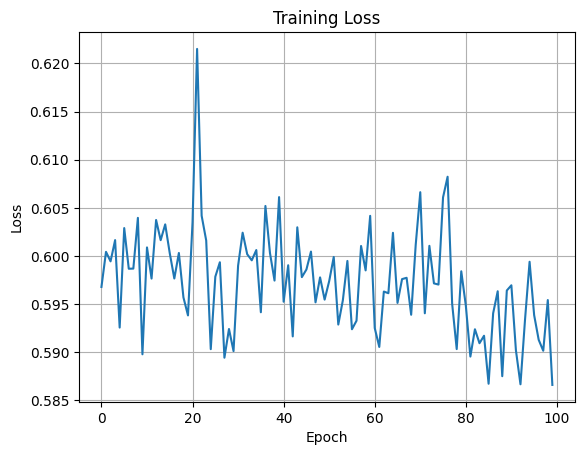

In [26]:
plt.plot(loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.grid(True)
plt.show()

New DATA

In [29]:
new_studen=np.array([[7,90,75]],dtype=np.float32)
new_scaler=scaler.transform(new_studen)
new_tensor=torch.tensor(new_scaler)

model.eval()
with torch.no_grad():
  prob=torch.sigmoid(model(new_tensor)).item()
  print(prob*100)
print('pass' if prob>0.5 else 'Fail')



79.47531342506409
pass
